# Lab 3 — Millions of TVs, Who Is Watching?

Name: Nazar Harbarchuk | Group: KM-41

## Setup

In [2]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/4")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


In [41]:
# Lab rules applied once here, so every task below uses the same definitions.

# The two broadcast weeks covered by the new files, and the ten Lab 1 networks.
BROADCAST_DAYS = [f"2024-10-{d}" for d in range(14, 28)]
TEN_NETWORKS = sorted(programs["network_code"].unique())

# Time: start_utc and end_utc are UTC, everything else in the dataset is US Eastern.
# Dropping the timezone after conversion keeps the sessions comparable with the
# naive Eastern timestamps in programs and viewings.
acr_sessions["start_et"] = acr_sessions["start_utc"].dt.tz_convert("America/New_York").dt.tz_localize(None)
acr_sessions["end_et"] = acr_sessions["end_utc"].dt.tz_convert("America/New_York").dt.tz_localize(None)

# Broadcast day runs 06:00-05:59 Eastern, as in Lab 1.
acr_sessions["broadcast_day"] = (acr_sessions["start_et"] - pd.Timedelta(hours=6)).dt.strftime("%Y-%m-%d")

acr_sessions["duration_min"] = (acr_sessions["end_et"] - acr_sessions["start_et"]).dt.total_seconds() / 60.0
acr_sessions["duration_h"] = acr_sessions["duration_min"] / 60.0

# Edit rule: drop every session shorter than 1 minute (channel surfing).
sessions_clean = acr_sessions[acr_sessions["duration_min"] >= 1.0].copy()

# In-tab: a TV is in-tab on a broadcast day if it has at least one session after the edit rule.
tvs_intab = sessions_clean.groupby("broadcast_day")["tv_id"].nunique()
intab_tv_days = tvs_intab.sum()

# Live sessions are the only ones that count as viewing a network.
live_sessions = sessions_clean[sessions_clean["session_type"] == "live"].copy()

# The panel as the yardstick: every H record with its average weight over its
# in-tab days in October 14-27. These weights stand for all US TV households.
panel_hh_days = daily_weights[(daily_weights["resp_type"] == "H") &
                              (daily_weights["broadcast_date"].astype(str).isin(BROADCAST_DAYS))]
panel_hh_weight = panel_hh_days.groupby("respondent_id")["weight"].mean()
US_TV_HOUSEHOLDS = panel_hh_weight.sum()

### Task 1.1 Five questions
**Answer:**

| Question | `acr_sessions` (Smart-TV data) | Lab 1 `viewings` (Panel data) |
| :--- | :--- | :--- |
| **Grain** | A single continuous viewing session on one smart TV device. | A single continuous viewing event by an individual person (or household). |
| **Key** | `session_id` (primary), `tv_id` (device), `hashed_ip` (weak/probabilistic household link). | `household_id`, `viewer_id` (deterministic link to attributes and weights). |
| **Coverage** | Convenience sample of 29,940 opted-in smart TVs (devices only, one per home). | Probability sample of representative households (all TVs and all people in the home). |
| **Weight** | Unweighted (raw counts of devices). | Weighted (`daily_weights`) to project to the entire US TV population. |
| **Provenance** | Passive Automatic Content Recognition (ACR) matching screen pixels/audio to a library. | Active/passive hardware people meters from a recruited panel. |

**Biggest difference:** **Coverage and Weight**. The ACR data is an unweighted convenience sample of single devices that misses non-opted-in homes, secondary TVs, and individual people. The panel is a weighted probability sample that represents the entire US population[cite: 9, 11].

## Task 1.2 Size and shape

In [42]:
tvs = acr_sessions["tv_id"].nunique()
sessions = len(acr_sessions)
broadcast_days = acr_sessions["broadcast_day"].nunique()
avg_tvs_intab = tvs_intab.mean()

# Both rates use the same denominator: in-tab TV-days after the edit rule.
hours_per_tv_raw = acr_sessions["duration_h"].sum() / intab_tv_days
hours_per_tv_clean = sessions_clean["duration_h"].sum() / intab_tv_days
share_dropped = (sessions - len(sessions_clean)) / sessions

print("TVs:", tvs)
print("Sessions:", sessions)
print("Broadcast days:", broadcast_days)
print("Average TVs in-tab per day:", f"{avg_tvs_intab:.1f}")
print("Hours per TV per day, raw:", f"{hours_per_tv_raw:.2f}")
print("Hours per TV per day, after edit rule:", f"{hours_per_tv_clean:.2f}")
print("Share of sessions dropped:", f"{share_dropped:.3f}")

TVs: 29940
Sessions: 6392981
Broadcast days: 14
Average TVs in-tab per day: 29074.1
Hours per TV per day, raw: 4.74
Hours per TV per day, after edit rule: 4.70
Share of sessions dropped: 0.299


## Task 1.3 What the TV could not see

In [43]:
total_hours = sessions_clean["duration_h"].sum()

by_type = (sessions_clean.groupby("session_type")["duration_h"].sum() / total_hours).sort_values(ascending=False)
by_input = (sessions_clean.groupby("input_source")["duration_h"].sum() / total_hours).sort_values(ascending=False)

print(f"{'session_type':<18} | {'share of hours':<14}")
print("-" * 35)
for name, share in by_type.items():
    print(f"{name:<18} | {share:<14.3f}")

print()
print(f"{'input_source':<18} | {'share of hours':<14}")
print("-" * 35)
for name, share in by_input.items():
    print(f"{name:<18} | {share:<14.3f}")

print()
print("Share of TV-on hours unknown (%):", f"{by_type['unknown'] * 100:.1f}")

session_type       | share of hours
-----------------------------------
unknown            | 0.396         
live               | 0.322         
app                | 0.257         
dvr                | 0.025         

input_source       | share of hours
-----------------------------------
built_in_app       | 0.307         
cable_box          | 0.276         
streaming_device   | 0.231         
antenna            | 0.086         
satellite_box      | 0.076         
game_or_disc       | 0.024         

Share of TV-on hours unknown (%): 39.6


**Answer:**
A real ACR feed might have even more `unknown` hours because it can only recognize content that is actively indexed in its reference fingerprint library (typically major live linear networks). Real users consume a vast amount of unindexed content, use features that distort the screen (menus, overlays, zooming), or watch time-shifted DVR content outside the vendor's matching window.

Two kinds of viewing that end up as `unknown`:
1. **Streaming / VOD:** Watching Netflix, YouTube, or Hulu via built-in smart TV apps or external streaming devices.
2. **Gaming & Physical Media:** Playing video games on a console (Xbox/PlayStation) or watching a DVD/Blu-ray disc[cite: 9, 11].

## Task 2.1 Match

In [44]:
# One row per TV with its hashed IP, and how many households that IP covers.
tv_ips = acr_sessions[["tv_id", "hashed_ip"]].drop_duplicates(subset=["tv_id"])
households_per_ip = hh_attributes.groupby("hashed_ip")["household_id"].nunique()

tv_ips = tv_ips.assign(hh_count=tv_ips["hashed_ip"].map(households_per_ip))

# Matched = the IP appears for exactly one household. A shared IP cannot be resolved.
matched_one = (tv_ips["hh_count"] == 1).mean()
matched_several = (tv_ips["hh_count"] > 1).mean()
matched_none = tv_ips["hh_count"].isna().mean()

print("Matched to one household (%):", f"{matched_one * 100:.1f}")
print("Shared IP, unresolved (%):", f"{matched_several * 100:.1f}")
print("Not matched (%):", f"{matched_none * 100:.1f}")

Matched to one household (%): 65.2
Shared IP, unresolved (%): 11.8
Not matched (%): 22.9


**Answer:** why an IP address is a weak key.

An IP address identifies a network connection at a moment in time, not a home, and the mapping is wrong in both directions. One IP can serve many homes — an apartment building behind one router, a dormitory, a shared office, and above all carrier-grade NAT, where an ISP puts hundreds of subscribers behind one address; here 11.8% of TVs land on such an address and cannot be resolved even though the home is in the file. The reverse also happens: addresses are assigned dynamically, so a home's IP changes after a router reboot or a lease renewal, and the address the vendor saw for the household file need not be the one the TV reported. Add a VPN, a mobile hotspot or a guest network and the link breaks completely; 22.9% of TVs match nothing at all. So two thirds of the footprint gets household attributes, and the third that does not is not a random third — it leans towards dense urban housing and towards homes behind CGNAT, which is exactly the kind of bias the profile in Task 2.2 then inherits.

## Task 2.2 Profile

In [45]:
# Footprint: the TVs that resolved to exactly one household.
matched_tvs = (tv_ips[tv_ips["hh_count"] == 1]
               .merge(hh_attributes.drop_duplicates(subset=["hashed_ip"]), on="hashed_ip", how="left"))

# Panel: household attributes are flags in viewer_attributes (region 841-844, income 811-816).
REGION_FLAGS = {841: "Northeast", 842: "Midwest", 843: "South", 844: "West"}
INCOME_FLAGS = {811: "Under $25k", 812: "$25k-$50k", 813: "$50k-$75k",
                814: "$75k-$100k", 815: "$100k-$150k", 816: "$150k+"}

def attribute_series(flag_map):
    """Map each household record to the one flag it carries from flag_map."""
    flags = viewer_attributes[viewer_attributes["attr_id"].isin(flag_map)]
    return flags.set_index("respondent_id")["attr_id"].map(flag_map)

panel = pd.DataFrame({"weight": panel_hh_weight})
panel["region"] = attribute_series(REGION_FLAGS).reindex(panel.index)
panel["income_band"] = attribute_series(INCOME_FLAGS).reindex(panel.index)

# The three income groups asked for, from the six bands both files share.
INCOME_GROUPS = {"Under $25k": "Under $50k", "$25k-$50k": "Under $50k",
                 "$50k-$75k": "$50-100k", "$75k-$100k": "$50-100k",
                 "$100k-$150k": "$100k+", "$150k+": "$100k+"}
panel["income_group"] = panel["income_band"].map(INCOME_GROUPS)
matched_tvs["income_group"] = matched_tvs["income_band"].map(INCOME_GROUPS)

def profile_rows(column, groups):
    """Unweighted footprint share next to the panel's weighted share, plus the index."""
    rows = []
    for group in groups:
        footprint_share = (matched_tvs[column] == group).mean()
        panel_share = panel.loc[panel[column] == group, "weight"].sum() / panel["weight"].sum()
        rows.append((group, footprint_share, panel_share, footprint_share / panel_share * 100))
    return rows

profile = pd.DataFrame(profile_rows("region", ["Northeast", "Midwest", "South", "West"]) +
                       profile_rows("income_group", ["Under $50k", "$50-100k", "$100k+"]),
                       columns=["group", "footprint_share", "panel_share", "index"])

print("Matched TVs profiled:", len(matched_tvs))
print()
print(f"{'group':<12} | {'footprint':<10} | {'panel':<10} | {'index':<6}")
print("-" * 48)
for _, row in profile.iterrows():
    print(f"{row['group']:<12} | {row['footprint_share']:<10.3f} | {row['panel_share']:<10.3f} | {row['index']:<6.1f}")

Matched TVs profiled: 19535

group        | footprint  | panel      | index 
------------------------------------------------
Northeast    | 0.150      | 0.170      | 88.0  
Midwest      | 0.201      | 0.210      | 96.0  
South        | 0.383      | 0.379      | 101.0 
West         | 0.266      | 0.241      | 110.4 
Under $50k   | 0.259      | 0.361      | 71.8  
$50-100k     | 0.320      | 0.289      | 110.8 
$100k+       | 0.421      | 0.350      | 120.1 


In [46]:
# The hint: the household file also carries the age of the head of household.
# In the panel the head of house is a person record (attr 701) with an age (attr 300);
# the id of a household record is the member id rounded down to the hundred.
AGE_BANDS = [(0, 34, "18-34"), (35, 49, "35-49"), (50, 64, "50-64"), (65, 200, "65+")]

person_age = viewer_attributes[viewer_attributes["attr_id"] == 300].set_index("respondent_id")["value"]
heads = pd.DataFrame({"respondent_id": viewer_attributes.loc[viewer_attributes["attr_id"] == 701, "respondent_id"].unique()})
heads["age"] = heads["respondent_id"].map(person_age)
heads["weight"] = ((heads["respondent_id"] // 100) * 100).map(panel_hh_weight)
heads = heads.dropna(subset=["age", "weight"])
heads["head_age_band"] = pd.cut(heads["age"],
                                bins=[-1] + [hi for _, hi, _ in AGE_BANDS],
                                labels=[label for _, _, label in AGE_BANDS])

print(f"{'head_age_band':<14} | {'footprint':<10} | {'panel':<10} | {'index':<6}")
print("-" * 50)
for band in [label for _, _, label in AGE_BANDS]:
    footprint_share = (matched_tvs["head_age_band"] == band).mean()
    panel_share = heads.loc[heads["head_age_band"] == band, "weight"].sum() / heads["weight"].sum()
    print(f"{band:<14} | {footprint_share:<10.3f} | {panel_share:<10.3f} | {footprint_share / panel_share * 100:<6.1f}")

head_age_band  | footprint  | panel      | index 
--------------------------------------------------
18-34          | 0.196      | 0.190      | 103.6 
35-49          | 0.348      | 0.303      | 115.0 
50-64          | 0.263      | 0.240      | 109.6 
65+            | 0.192      | 0.267      | 71.8  


**Answer:** which groups are over/under-represented, and one reason.

By region the footprint is close to the panel but tilted west: the West is over-represented (index 110) and the Northeast under-represented (index 88), with the Midwest slightly low (96) and the South on the nose (101). By income the skew is much larger and runs in one direction: homes under $50k are at index 72 — 25.9% of the footprint against 36.1% of US households — while $50-100k sits at 111 and $100k+ at 120 (42.1% against 35.0%). The head-of-household table shows the same thing by age: 65+ is at index 72, with 35-49 (115) and 50-64 (110) over-represented.

**One reason.** Nothing recruited this sample; it selected itself, and every step of the selection favours the same kind of home. You only appear in it if you bought a recent connected smart TV, connected it to broadband, and left ACR switched on in the setup menu — a purchase and a default that follow income, newer housing and younger, more technical heads of household. The poorest and the oldest homes are the ones still on an older set, a set-top box or an antenna, or the ones most likely to have refused the data clause, so they fall out. Then the IP join in Task 2.1 removes another third of the TVs, and it removes them in the same direction, since the apartment buildings and CGNAT addresses it cannot resolve are not spread evenly across income. Bigger is not more representative: a 29,940-TV sample skewed this way is still a sample of richer, younger, western homes.

## Task 2.3 — Ratings

In [47]:
def tvs_that_watched(telecast):
    """TVs whose live sessions on that network overlap the telecast by at least 1 minute."""
    candidates = live_sessions[(live_sessions["network_code"] == telecast["network_code"]) &
                               (live_sessions["start_et"] < telecast["end_ts"]) &
                               (live_sessions["end_et"] > telecast["start_ts"])].copy()
    overlap_start = candidates["start_et"].clip(lower=telecast["start_ts"])
    overlap_end = candidates["end_et"].clip(upper=telecast["end_ts"])
    overlap_min = (overlap_end - overlap_start).dt.total_seconds() / 60.0
    return candidates.loc[overlap_min >= 1.0, "tv_id"].nunique()

telecasts = reference_ratings.merge(programs, on="telecast_id")

rows = []
for _, telecast in telecasts.iterrows():
    broadcast_day = str(telecast["broadcast_date"])
    watched = tvs_that_watched(telecast)
    # Every TV counts once: this is an unweighted rating.
    tv_rating = watched / tvs_intab[broadcast_day] * 100
    rows.append({"program_name": telecast["program_name"],
                 "network_code": telecast["network_code"],
                 "broadcast_date": broadcast_day,
                 "tvs_watched": watched,
                 "tv_rating": tv_rating,
                 "reference": telecast["hh_rating"],
                 "ratio": tv_rating / telecast["hh_rating"]})

ratings = pd.DataFrame(rows).sort_values("ratio")

print(f"{'telecast':<36} | {'net':<6} | {'date':<11} | {'TVs HH rating':<13} | {'reference':<9} | {'ratio':<5}")
print("-" * 100)
for _, row in ratings.iterrows():
    print(f"{row['program_name'][:36]:<36} | {row['network_code']:<6} | {row['broadcast_date']:<11} | "
          f"{row['tv_rating']:<13.1f} | {row['reference']:<9.1f} | {row['ratio']:<5.2f}")

telecast                             | net    | date        | TVs HH rating | reference | ratio
----------------------------------------------------------------------------------------------------
Hannity                              | FNC    | 2024-10-16  | 0.8           | 2.3       | 0.36 
NCIS                                 | CBS    | 2024-10-14  | 5.4           | 10.6      | 0.51 
Unsellable Houses                    | HGTV   | 2024-10-16  | 2.1           | 3.7       | 0.57 
The Real Housewives of New York City | BRAVO  | 2024-10-15  | 0.7           | 1.2       | 0.60 
Halloween Baking Championship        | FOOD   | 2024-10-14  | 1.0           | 1.6       | 0.60 
MLB Postseason                       | FOX    | 2024-10-25  | 16.5          | 25.9      | 0.64 
Grotesquerie                         | FX     | 2024-10-16  | 2.3           | 3.5       | 0.64 
NFL Football                         | NBC    | 2024-10-27  | 21.2          | 33.1      | 0.64 


**Answer:** which are too high or low, and does it fit the profile?

Every one of the eight is **too low** — the ratios run from 0.36 to 0.64, so the footprint understates the currency by a third to two thirds. That is the part of the story that is the same for all eight telecasts, and it has nothing to do with who is in the sample. Two things push every rating the same way. First, the footprint sees one set per home while a US household has about 2.6 sets, of which only about 1.1 is of the same brand: a home watching NCIS on the bedroom TV is a viewing household for the currency and a non-viewer here (Task 3 measures that gap). Second, the numerator only counts what the fingerprint recognized as `live` on that network, and 39.6% of in-tab hours are `unknown` — a home watching NBC through a vMVPD app lands in `app`, with no network at all, and is lost from the numerator while staying in the denominator.

The interesting part is the spread between the eight, and that is where the profile shows up. **Hannity (FNC) is furthest off at 0.36**, with **NCIS (CBS) next at 0.51** — the two telecasts whose audiences skew oldest. **The World Series (FOX, 0.64), Sunday Night Football (NBC, 0.64) and Grotesquerie (FX, 0.64) are closest**, with Housewives (BRAVO, 0.60) and the Food Network bake-off (0.60) beside them. This fits the Task 2.2 profile exactly: homes with a head 65+ are at index 72 and homes under $50k at index 72, so the programmes those homes carry lose the most, while the young, affluent audiences of FX, Bravo and live sport are the ones the footprint holds in roughly the right proportion. Big live sport also wins twice over, because it is watched on the main set in the living room, the one set the footprint actually sees.

So the gap has two parts: a large common deficit from missing sets and unrecognized content, which a single correction factor could in principle rescale, and a demographic skew on top of it, which it could not — rescaling to fix Hannity would then overstate the NFL. That is the Lab 4 problem.

## Task 3.1 — Hours per home

In [48]:
# Smart TVs: live sessions on the ten Lab 1 networks, per in-tab TV-day.
live_ten = live_sessions[live_sessions["network_code"].isin(TEN_NETWORKS)]
tv_live_hours_per_day = live_ten["duration_h"].sum() / intab_tv_days

# Panel: H records on the same ten networks over the same two weeks, weighted.
panel_live = viewings[(viewings["resp_type"] == "H") &
                      (viewings["network_code"].isin(TEN_NETWORKS)) &
                      (viewings["playback"] == "Live")].copy()
panel_live["broadcast_day"] = (panel_live["start_ts"] - pd.Timedelta(hours=6)).dt.strftime("%Y-%m-%d")
panel_live = panel_live[panel_live["broadcast_day"].isin(BROADCAST_DAYS)]
panel_live["duration_h"] = (panel_live["end_ts"] - panel_live["start_ts"]).dt.total_seconds() / 3600.0

# Denominator: weighted in-tab household-days over the same fortnight.
panel_hh_day_weight = panel_hh_days["weight"].sum()
panel_live_hours_per_day = (panel_live["duration_h"] * panel_live["weight"]).sum() / panel_hh_day_weight

print("Live hours per TV per day (ten networks):", f"{tv_live_hours_per_day:.2f}")
print("Live hours per panel household per day (ten networks):", f"{panel_live_hours_per_day:.2f}")
print("Footprint as a share of the panel:", f"{tv_live_hours_per_day / panel_live_hours_per_day:.3f}")

Live hours per TV per day (ten networks): 0.87
Live hours per panel household per day (ten networks): 1.92
Footprint as a share of the panel: 0.452


**Answer:** which is lower and why.

The **footprint is lower**: 0.87 live hours per in-tab TV per day against 1.92 per in-tab panel household, so it captures 0.45 of the panel's level — a shortfall of about 1.05 hours, or 55%, per home per day.

The denominators are not the same thing, and that is most of the gap. The panel measures a *household*: every set in the home is metered, and a US home has about 2.6 of them. The footprint measures a *set* — one opted-in smart TV, since there is one `tv_id` per home here, and in a real feed only about 1.1 of a home's sets carry the same brand's ACR anyway. Viewing that happens on the second set in the bedroom or the kitchen, on the older TV downstairs, or on a tablet is household viewing the panel books and the footprint simply cannot see.

The rest is content the footprint sees but cannot name. Only `live` sessions carry a network, so anything watched through a vMVPD or a network app arrives as `app` with an empty `network_code`, and 39.6% of in-tab hours are `unknown` outright. Those hours are real viewing of these ten networks in part, but they are unattributable, so they drop out of the numerator while the TV still counts in the denominator. The two effects compound, which is why a device-level hour count cannot be read as a household hour count — and why the ratings in Task 2.3 come out a third to two thirds low across the board.

## Task 3.2 — Network shares

In [49]:
tv_shares = live_ten.groupby("network_code")["duration_h"].sum()
tv_shares = tv_shares / tv_shares.sum()

panel_shares = panel_live.assign(weighted_h=panel_live["duration_h"] * panel_live["weight"]) \
                         .groupby("network_code")["weighted_h"].sum()
panel_shares = panel_shares / panel_shares.sum()

network_shares = pd.DataFrame({"tv_share": tv_shares, "panel_share": panel_shares})
network_shares["index"] = network_shares["tv_share"] / network_shares["panel_share"] * 100
network_shares = network_shares.sort_values("panel_share", ascending=False)

print(f"{'network':<9} | {'share in TVs':<12} | {'share in panel':<14} | {'index':<6}")
print("-" * 50)
for network, row in network_shares.iterrows():
    print(f"{network:<9} | {row['tv_share']:<12.3f} | {row['panel_share']:<14.3f} | {row['index']:<6.1f}")

network   | share in TVs | share in panel | index 
--------------------------------------------------
NBC       | 0.214        | 0.206          | 103.6 
CBS       | 0.182        | 0.196          | 92.8  
FOX       | 0.201        | 0.194          | 103.9 
ABC       | 0.196        | 0.187          | 104.8 
FNC       | 0.085        | 0.110          | 77.4  
HGTV      | 0.034        | 0.031          | 110.4 
FOOD      | 0.024        | 0.022          | 108.9 
FX        | 0.028        | 0.022          | 129.1 
HIST      | 0.019        | 0.019          | 103.6 
BRAVO     | 0.016        | 0.013          | 122.0 


**Answer:** which networks the smart-TV data over- or under-states.

Shares are much better behaved than levels — the four broadcast networks come out within a few points of the panel (NBC 104, FOX 104, ABC 105, CBS 93), because dividing by the footprint's own total cancels the missing sets and the unknown hours as long as they hit every network alike. They do not hit every network alike, and the residual is the profile again.

**Understated: Fox News, badly** — 8.5% of footprint live hours against 11.0% in the panel, index 77 — and CBS mildly (93). These are the two oldest audiences among the ten, and the footprint is short of exactly those homes: heads 65+ at index 72, homes under $50k at index 72.

**Overstated: the young cable networks** — FX at index 129 (2.8% against 2.2%) and Bravo at 122, with HGTV 110 and Food Network 109 a step behind. These are the audiences the opted-in footprint has too many of.

So the footprint would sell a planner a schedule that looks younger than the country is: it would under-price Fox News inventory and over-state what FX and Bravo deliver. Note that the error here is a tenth to a third of a share point, while the error in levels in Task 3.1 was 55% — a reminder that this feed is far more usable for mix than for magnitude.

## Task 3.3 — What each can see
**Answer:** two or three things each way.

**What the panel can see and this feed cannot**

1. **People.** The panel's R and L records are individuals with age, sex, education and employment, so it can report an A25-54 rating directly. The footprint has no persons at all; it knows a set was on, not who was in front of it, and the bonus below can only reach persons by borrowing the panel's VPVH.
2. **The whole home.** Every set in the household is metered, so household reach, duplication between sets and total household tuning are measurable. The footprint sees one set and is blind to the other ~1.6.
3. **A known universe.** Every respondent carries a daily weight, so counts project to 125.8M US TV households. The footprint has no weights and no frame, so it cannot be projected at all — and as Task 2.2 shows, it should not be projected as if it were representative.
4. **Who was missing.** The panel knows its own in-tab status day by day, so a lost meter is visible and correctable; in the footprint a vanished TV is indistinguishable from a TV nobody switched on (see the broken day in Task 4.2).

**What this feed can see and the panel's ten-network files cannot**

1. **All of the dial.** 51 networks here against the panel's ten — cable, Spanish-language, sports and news channels the Lab 1 files never record.
2. **Everything else on the screen.** `app` hours, `game_or_disc`, DVR playback and the `input_source` column: how the home receives television at all. The panel files carry live viewing of ten networks and nothing else.
3. **Scale and granularity at the set level.** 29,940 TVs against ~4,100 households, second-by-second and with a DMA code, so small cable dayparts and local markets that are a zero cell in the panel still have observations here — the sampling-error argument in Task 5.1.
4. **Device and household attributes for cheap.** The compiled file adds income, children, household size and modelled signals such as `new_car_intender_6mo` on two thirds of the TVs, which the panel does not collect.

## Task 4.1 — Daily plots

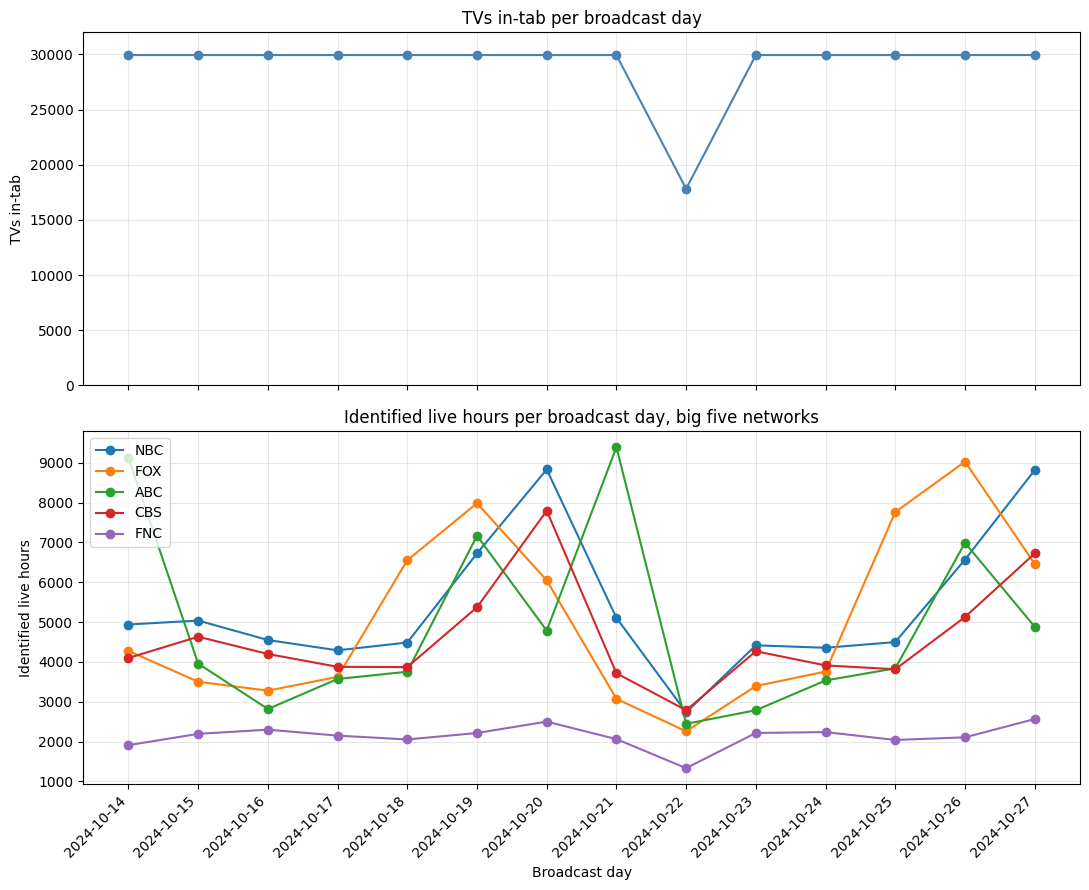

In [50]:
BIG_FIVE = tv_shares.nlargest(5).index.tolist()

# Identified live hours = live sessions with a recognized network.
daily_network_hours = (live_ten.groupby(["broadcast_day", "network_code"])["duration_h"].sum()
                               .unstack(fill_value=0.0).reindex(BROADCAST_DAYS))

fig, axes = plt.subplots(2, 1, figsize=(11, 9), sharex=True)

axes[0].plot(tvs_intab.reindex(BROADCAST_DAYS).index, tvs_intab.reindex(BROADCAST_DAYS).values,
             marker="o", color="steelblue")
axes[0].set_title("TVs in-tab per broadcast day")
axes[0].set_ylabel("TVs in-tab")
axes[0].set_ylim(0, 32000)
axes[0].grid(True, alpha=0.3)

for network in BIG_FIVE:
    axes[1].plot(daily_network_hours.index, daily_network_hours[network], marker="o", label=network)
axes[1].set_title("Identified live hours per broadcast day, big five networks")
axes[1].set_xlabel("Broadcast day")
axes[1].set_ylabel("Identified live hours")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Task 4.2 — Spike and broken day

In [51]:
# Biggest spike: the network and broadcast day with the most identified live hours.
spike_day, spike_network = daily_network_hours.stack().idxmax()
spike_hours = daily_network_hours.stack().max()

# A data problem moves the denominator, not the rate: look for a day where in-tab TVs
# collapse while hours per in-tab TV stay normal.
daily = pd.DataFrame({"tvs_intab": tvs_intab.reindex(BROADCAST_DAYS),
                      "hours": sessions_clean.groupby("broadcast_day")["duration_h"].sum().reindex(BROADCAST_DAYS)})
daily["hours_per_tv"] = daily["hours"] / daily["tvs_intab"]
broken_day = daily["tvs_intab"].idxmin()

print("Biggest spike (date, network):", spike_day, spike_network)
print("Identified live hours that day:", f"{spike_hours:.2f}")
print("What aired:")
for _, p in programs[(programs["network_code"] == spike_network) &
                     (programs["broadcast_date"].astype(str) == spike_day) &
                     (programs["daypart"] == "Prime")].iterrows():
    episode = "" if pd.isna(p["episode_name"]) else f" — {p['episode_name']}"
    print(f"  {p['start_ts'].strftime('%H:%M')}-{p['end_ts'].strftime('%H:%M')}  {p['program_name']}{episode}")

print()
print("Broken day (date):", broken_day)
print()
print(f"{'broadcast day':<15} | {'TVs in-tab':<11} | {'hours':<12} | {'hours per in-tab TV':<19}")
print("-" * 68)
for day, row in daily.iterrows():
    flag = "  <-- broken" if day == broken_day else ""
    print(f"{day:<15} | {row['tvs_intab']:<11.0f} | {row['hours']:<12.2f} | {row['hours_per_tv']:<19.2f}{flag}")

# Weekends run almost an hour per TV higher, so compare the broken Tuesday
# with the other weekdays only.
is_weekday = pd.to_datetime(daily.index).day_of_week < 5
other_weekdays = daily[is_weekday & (daily.index != broken_day)]

print()
print("TVs in-tab on the broken day as a share of a normal weekday:",
      f"{daily.loc[broken_day, 'tvs_intab'] / other_weekdays['tvs_intab'].mean():.3f}")
print("Hours on the broken day as a share of a normal weekday:",
      f"{daily.loc[broken_day, 'hours'] / other_weekdays['hours'].mean():.3f}")
print("Hours per in-tab TV, broken day vs normal weekday:",
      f"{daily.loc[broken_day, 'hours_per_tv']:.2f}", "vs", f"{other_weekdays['hours_per_tv'].mean():.2f}")

Biggest spike (date, network): 2024-10-21 ABC
Identified live hours that day: 9392.46
What aired:
  20:00-20:15  Who Wants to Be a Millionaire
  20:15-23:25  NFL Football — NFL Football: BAL @ TB

Broken day (date): 2024-10-22

broadcast day   | TVs in-tab  | hours        | hours per in-tab TV
--------------------------------------------------------------------
2024-10-14      | 29940       | 135257.43    | 4.52               
2024-10-15      | 29940       | 133543.88    | 4.46               
2024-10-16      | 29940       | 133115.80    | 4.45               
2024-10-17      | 29940       | 131951.90    | 4.41               
2024-10-18      | 29940       | 131460.60    | 4.39               
2024-10-19      | 29940       | 158983.42    | 5.31               
2024-10-20      | 29940       | 159161.69    | 5.32               
2024-10-21      | 29940       | 136378.94    | 4.56               
2024-10-22      | 17818       | 79258.87     | 4.45                 <-- broken
2024-10-23      | 299

**Answer:** what aired; what went wrong with the data; drop, fix or flag?

**The spike.** The largest single network-day is **ABC on 2024-10-21**, 9,392 identified live hours — and the night before it in the ranking is ABC on 2024-10-14, with FOX on 10-26 and NBC on 10-20 and 10-27 just behind. The schedule explains all of them: Monday 21 October ABC carried **Monday Night Football, Baltimore at Tampa Bay, 20:15-23:25**, a three-hour live event in prime on a broadcast network. The same pattern repeats as ABC's other Monday (10-14), the two Sundays of NFL on NBC and FOX, and FOX from 25 October when the World Series starts. Live sport is the one thing that still assembles a mass simultaneous audience on one network, and it is exactly the viewing this feed is best at: it happens on the main set, live, on an indexed network, so none of the footprint's three blind spots apply.

**The broken day.** On **2024-10-22** in-tab TVs fall from 29,940 to **17,818** — 0.595 of a normal day — and total session hours fall by the same 40%, while **hours per in-tab TV stay at 4.45 against 4.39-4.56 on the neighbouring days**. That signature is the giveaway: the audience did not change, the collection did. The TVs that remain behave exactly as always; 12,122 TVs simply report nothing at all. They are spread across all 39 DMAs and across the whole id range, and the sessions that did arrive keep their normal hourly shape, so this is a collection or ingest outage — a dropped feed partition, a failed upload batch — not a blackout, a holiday or a real viewing event.

**What it would distort.** Anything with a count in it. Daily totals — total hours, impressions, identified live hours per network — come out 40% low, and a trend chart shows a crater that a planner would read as audience collapse. Ratings are subtler: `watched ÷ in-tab × 100` has the loss in both numerator and denominator, so a rating computed *per day* survives roughly intact. But a rating computed against a fixed denominator (29,940 TVs, or a fortnight average) would be understated by 40%, and any fortnight average of daily totals is pulled down by about 3%. The danger is precisely that the per-day rating still looks plausible while every level is wrong.

**Drop, fix or flag?** **Flag it, and exclude it from level metrics; do not try to fix it.** Flag, because the cause is outside the data and the loss is not something to impute: inventing 12,122 TV-days of viewing would be fabrication, and nothing in the file says whether the missing TVs are a random 40% or a 40% correlated with region or device. Exclude from anything that sums — daily totals, reach, fortnight hour counts should run on the other 13 days — and keep using it for per-day rates, which hold up, with the caveat printed next to the number. And ask the vendor what happened, because an outage this large going undocumented is itself a finding about the feed: a due-diligence report should say that the vendor shipped a 40% loss day with no flag in the file, and that the agency would need an in-tab or delivery-quality field before it could trust the daily series at all.

## Task 5.1 — Sampling error vs bias

In [52]:
import numpy as np

SE_TELECASTS = ["NFL Football", "Hannity", "Unsellable Houses"]

rows = []
for name in SE_TELECASTS:
    telecast = ratings[ratings["program_name"] == name].iloc[0]
    broadcast_day = telecast["broadcast_date"]

    # p = the reference rating, as a proportion.
    p = telecast["reference"] / 100.0
    n_footprint = tvs_intab[broadcast_day]
    n_panel = daily_weights[(daily_weights["resp_type"] == "H") &
                            (daily_weights["broadcast_date"].astype(str) == broadcast_day)]["respondent_id"].nunique()

    # SE in rating points.
    se_footprint = np.sqrt(p * (1 - p) / n_footprint) * 100
    se_panel = np.sqrt(p * (1 - p) / n_panel) * 100

    rows.append({"program_name": name, "broadcast_date": broadcast_day,
                 "n_footprint": n_footprint, "n_panel": n_panel,
                 "se_footprint": se_footprint, "se_panel": se_panel,
                 "se_ratio": se_panel / se_footprint,
                 "bias": telecast["tv_rating"] - telecast["reference"]})

se_table = pd.DataFrame(rows)

print(f"{'telecast':<20} | {'n TVs':<7} | {'n panel':<8} | {'SE footprint':<12} | {'SE panel':<9} | {'TVs - reference':<15}")
print("-" * 92)
for _, row in se_table.iterrows():
    print(f"{row['program_name']:<20} | {row['n_footprint']:<7.0f} | {row['n_panel']:<8.0f} | "
          f"{row['se_footprint']:<12.2f} | {row['se_panel']:<9.2f} | {row['bias']:<15.1f}")

print()
for _, row in se_table.iterrows():
    print(f"{row['program_name']}: footprint SE is {row['se_ratio']:.1f}x smaller, "
          f"but the gap to the reference is {abs(row['bias']) / row['se_footprint']:.0f} footprint SEs wide")

telecast             | n TVs   | n panel  | SE footprint | SE panel  | TVs - reference
--------------------------------------------------------------------------------------------
NFL Football         | 29940   | 3898     | 0.27         | 0.75      | -11.9          
Hannity              | 29940   | 3867     | 0.09         | 0.24      | -1.5           
Unsellable Houses    | 29940   | 3867     | 0.11         | 0.30      | -1.6           

NFL Football: footprint SE is 2.8x smaller, but the gap to the reference is 44 footprint SEs wide
Hannity: footprint SE is 2.8x smaller, but the gap to the reference is 17 footprint SEs wide
Unsellable Houses: footprint SE is 2.8x smaller, but the gap to the reference is 15 footprint SEs wide


**Answer:** which error is bigger, and does more data shrink it?

Sampling error is 2.8 times smaller in the footprint for every one of the three telecasts, because n goes from ~3,870 panel households to 29,940 TVs and the standard error falls with √n: Sunday Night Football 0.27 rating points against 0.75, Hannity 0.09 against 0.24, Unsellable Houses 0.11 against 0.30. On precision alone the vendor's deck is right.

**And it does not matter, because the other error is one to two orders of magnitude bigger.** The footprint misses Sunday Night Football by **-11.9 rating points** — 44 of its own standard errors. Hannity is off by -1.5 points (17 SEs) and Unsellable Houses by -1.6 (15 SEs). A 95% confidence interval from the footprint would be 21.2 ± 0.5, and the true answer, 33.1, is nowhere near it. The interval is narrow and wrong, which is worse than wide and right, because narrowness is what invites someone to believe it.

**Does more data shrink it? No.** Sampling error comes from how *many* units you observed and falls with √n. Bias comes from *which* units you observed and from what the instrument cannot see — opted-in homes skewed rich and young, one set out of 2.6, 39.6% of hours unrecognized — and none of those change when the vendor adds TVs. Triple the panel to 300,000 opted-in TVs and the SE halves again while the -11.9 point gap sits exactly where it was. That is the whole lesson: a big sample buys precision, and only a representative sample buys accuracy. The fix is not more rows, it is weighting and calibration against a probability sample — which is Lab 4.

## Task 5.2 — Answer to the planner
**Answer:** 5-7 sentences.

From this feed Sunday Night Football (Dallas at San Francisco, NBC, 27 October) comes out at a **21.2 household rating** — 6,362 of 29,940 in-tab smart TVs — and I would not put that number in a client deck, because the currency for the same telecast is 33.1 and the feed is understating it by a third. The gap is not sampling noise: with 29,940 TVs the sampling error is ±0.3 rating points, so the 11.9-point shortfall is roughly 44 standard errors, and it would not get any smaller if the vendor sold us ten times the TVs. It is what the feed structurally cannot see — it measures one opted-in set in a home that owns about 2.6, it knows nothing about people (so there is no A25-54 in it at all without borrowing the panel's VPVH), it cannot name content watched through apps or a vMVPD, 39.6% of its in-tab hours are unrecognized, and the homes that opted in and resolved to a household skew affluent, younger and western, with homes under $50k and heads 65+ both at about 72% of their true weight. The one number I can give you today with a straight face is a **relative** one: the feed's own share of live hours by network tracks the panel within a few points, so it is usable for mix and for ranking telecasts against each other, not for levels. I should also flag that 22 October arrives with 40% of its TVs missing — a vendor-side outage, not an audience event — so nothing that sums across days should be quoted until that is resolved. Before this feed goes near a plan I would need weights calibrated against the panel or the currency, a sets-per-home and ACR-coverage correction, a documented in-tab or delivery-quality field so we can see days like the 22nd ourselves, and a persons layer — and I would validate the whole thing on telecasts where we already know the answer. Give me the panel-based number for tomorrow's presentation and let me run the calibration on the footprint for the next flight; that is Lab 4's job, and until it is done this feed is a diagnostic tool, not a currency.

## Bonus

In [53]:
# VPVH = A25-54 persons (R and L) who watched, divided by households (H) that watched,
# both by the Lab 1 viewing rule and weighted with that day's weights.
snf = telecasts[telecasts["program_name"] == "NFL Football"].iloc[0]
snf_day = str(snf["broadcast_date"])

def panel_respondents_who_watched(telecast):
    """Respondent ids whose viewing overlaps the telecast by at least 1 minute."""
    candidates = viewings[(viewings["network_code"] == telecast["network_code"]) &
                          (viewings["start_ts"] < telecast["end_ts"]) &
                          (viewings["end_ts"] > telecast["start_ts"])].copy()
    overlap_start = candidates["start_ts"].clip(lower=telecast["start_ts"])
    overlap_end = candidates["end_ts"].clip(upper=telecast["end_ts"])
    overlap_min = (overlap_end - overlap_start).dt.total_seconds() / 60.0
    return candidates[overlap_min >= 1.0]

watchers = panel_respondents_who_watched(snf)
day_weight = daily_weights[daily_weights["broadcast_date"].astype(str) == snf_day].set_index("respondent_id")["weight"]

is_a2554 = person_age.between(25, 54)
a2554_ids = set(person_age[is_a2554].index)

hh_watchers = watchers.loc[watchers["resp_type"] == "H", "respondent_id"].unique()
person_watchers = watchers.loc[watchers["resp_type"].isin(["R", "L"]), "respondent_id"].unique()
a2554_watchers = [r for r in person_watchers if r in a2554_ids]

weighted_hh = day_weight.reindex(hh_watchers).sum()
weighted_a2554 = day_weight.reindex(a2554_watchers).sum()
vpvh = weighted_a2554 / weighted_hh

# Both universes from the panel's weights: average weight over in-tab days, Oct 14-27.
panel_person_days = daily_weights[(daily_weights["resp_type"].isin(["R", "L"])) &
                                  (daily_weights["broadcast_date"].astype(str).isin(BROADCAST_DAYS))]
panel_person_weight = panel_person_days.groupby("respondent_id")["weight"].mean()
US_A2554_PERSONS = panel_person_weight[panel_person_weight.index.isin(a2554_ids)].sum()

tv_hh_rating = ratings.loc[ratings["program_name"] == "NFL Football", "tv_rating"].iloc[0]
a2554_rating = tv_hh_rating * vpvh * (US_TV_HOUSEHOLDS / US_A2554_PERSONS)

print("Telecast:", snf["program_name"], "|", snf["network_code"], "|", snf_day)
print("Households (H) that watched, weighted (M):", round(weighted_hh / 1_000_000, 2))
print("A25-54 persons (R, L) that watched, weighted (M):", round(weighted_a2554 / 1_000_000, 2))
print("VPVH A25-54:", round(vpvh, 3))
print("US TV households from the panel's weights (M):", round(US_TV_HOUSEHOLDS / 1_000_000, 2))
print("US A25-54 persons from the panel's weights (M):", round(US_A2554_PERSONS / 1_000_000, 2))
print("TVs' household rating (%):", round(tv_hh_rating, 1))
print("A25-54 rating (persons):", round(a2554_rating, 1))

Telecast: NFL Football | NBC | 2024-10-27
Households (H) that watched, weighted (M): 43.02
A25-54 persons (R, L) that watched, weighted (M): 22.06
VPVH A25-54: 0.513
US TV households from the panel's weights (M): 133.23
US A25-54 persons from the panel's weights (M): 130.85
TVs' household rating (%): 21.2
A25-54 rating (persons): 11.1


**Answer:** what this assumes.

The estimate is **VPVH A25-54 = 0.513** and an **A25-54 rating of 11.1** from the footprint's 21.2 household rating. (For scale: applying the same VPVH to the currency's 33.1 household rating gives 17.3, so the footprint understates the persons rating by as much as it understates households — the bonus converts the number, it does not repair it.) The VPVH is below 1 because it is demo-specific: it counts only 25-54s, and many of the 43.0M households watching Sunday Night Football contain no one in that age band at all, while others contain two or three.

What the arithmetic assumes:

1. **That the footprint's homes have the same people in them as the panel's.** This is the big one, and Task 2.2 says it is false. VPVH is imported wholesale from the panel, so the estimate presumes the 29,940 opted-in homes have the same household size, age composition and co-viewing habits as US homes. They do not: the footprint is short of homes with a head 65+ (index 72) and of homes under $50k (index 72), and over-weight on heads 35-49 (index 115) — a profile that in reality carries *more* 25-54s per viewing home than average, so the true VPVH for these homes is probably above 0.513 and the estimate is biased low on top of the household rating already being low.
2. **That a household rating can be rescaled into a persons rating at all.** The formula treats viewing as if every viewing household contributed its demographic share mechanically. It cannot know who was actually in the room: a household rating says a set was tuned, not that a 25-54 was watching it, and the panel's own person-level log-in is the only thing in this dataset that distinguishes the two.
3. **That one telecast's VPVH is stable.** It is measured on a single Sunday night from the households that watched one game, and it is applied to a different sample of homes on the same night. Co-viewing on a marquee live sports telecast is unusually high, so this VPVH does not transfer to another programme, another daypart or another night.
4. **That the two universes are commensurable.** Both come from the panel's weights — 133.2M TV households and 130.8M A25-54 persons, from each respondent's average weight over its in-tab days in 14-27 October. Note that 133.2M overshoots the 125.8M headline universe by about 6%, because averaging each household's weight over only the days it was in-tab and then summing over every household that was ever in-tab does not reproduce a single day's projection; the ratio of the two universes is what enters the formula and both are built the same way, so most of that error cancels, but neither figure should be quoted on its own as a universe estimate. More importantly, this is the panel's universe, not the footprint's, and the footprint has no universe of its own. The whole estimate is the panel's structure wearing the footprint's numerator, which is a reasonable thing to show a planner only with all four caveats attached.